# Machine Learning – Midterm Assignment
## Sections 11–12: Comparing the Two Datasets and Run Inventory

This notebook does **not** fit any model. It only reads the six CSV files and the figures written by `breast_cancer.ipynb` and `wine.ipynb` (run those two notebooks first), checks the required row counts and answers the comparison questions with the recorded results.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

RESULTS_DIR = Path("results")
FIG_DIR = Path("figures")
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.precision", 4)

runs = pd.read_csv(RESULTS_DIR / "classifier_runs.csv")
summary = pd.read_csv(RESULTS_DIR / "classifier_summary.csv")
clf_test = pd.read_csv(RESULTS_DIR / "classifier_test.csv")
km_runs = pd.read_csv(RESULTS_DIR / "kmeans_runs.csv")
km_summary = pd.read_csv(RESULTS_DIR / "kmeans_summary.csv")
km_test = pd.read_csv(RESULTS_DIR / "kmeans_test.csv")
DATASETS = ["breast_cancer", "wine"]

## Final tables for both datasets

**Final classifier test table (two rows: one selected seed-42 classifier per dataset)**

In [2]:
assert len(clf_test) == 2
display(clf_test)

,dataset,selected_config,evaluation_seed,val_macro_f1_mean,val_macro_f1_std,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc
0,breast_cancer,breast_cancer_knn_scaled_k7,42,0.9677,0.0297,0.9737,0.98,0.9643,0.9713,0.9888
1,wine,wine_knn_scaled_k11,42,0.9814,0.0323,1.0000,1.00,1.0000,1.0000,1.0000


**K-Means: across-seed validation summary (four rows) and final test table (four rows, seed 42)**

In [3]:
assert len(km_summary) == 4 and len(km_test) == 4
display(km_summary)
with pd.option_context("display.max_colwidth", None):
    display(km_test)

,dataset,representation,n_runs,train_inertia_mean,train_inertia_std,val_ari_mean,val_ari_std,val_ari_valid_count,val_silhouette_mean,val_silhouette_std,val_silhouette_valid_count
0,breast_cancer,unscaled,3,5.1271e+07,1.9496e+06,0.5043,0.1064,3,0.6773,0.0334,3
1,breast_cancer,scaled,3,7.9481e+03,4.7574e+01,0.5813,0.1424,3,0.3121,0.0547,3
2,wine,unscaled,3,1.3483e+06,4.3581e+04,0.3613,0.0680,3,0.5765,0.1014,3
3,wine,scaled,3,8.7914e+02,9.8609e+00,1.0000,0.0000,3,0.2751,0.0248,3


,dataset,representation,seed,n_clusters,n_test_samples,test_cluster_counts,test_distinct_clusters,test_ari,test_silhouette
0,breast_cancer,unscaled,42,2,114,cluster 0: 86; cluster 1: 28,2,0.5585,0.7120
1,breast_cancer,scaled,42,2,114,cluster 0: 74; cluster 1: 40,2,0.7354,0.3251
2,wine,unscaled,42,3,36,cluster 0: 14; cluster 1: 10; cluster 2: 12,3,0.3733,0.4929
3,wine,scaled,42,3,36,cluster 0: 13; cluster 1: 13; cluster 2: 10,3,0.9088,0.2711


## 11. Comparing the Two Datasets

Each question is answered with the recorded results of the two notebooks.

### 11.1 Did the same classifier and representation perform best on both datasets?

In [4]:
selected = summary[summary["selected"]][["dataset", "config_id", "algorithm", "representation", "parameter",
                                         "val_macro_f1_mean", "val_macro_f1_std", "val_accuracy_mean"]]
print("Selected configuration per dataset (validation results only):")
display(selected)

print("Best configuration of each algorithm on validation (mean macro-F1), per dataset:")
best_per_algo = (summary.sort_values("selection_rank")
                 .groupby(["dataset", "algorithm"], sort=False).head(1)
                 [["dataset", "algorithm", "config_id", "val_macro_f1_mean", "val_macro_f1_std", "selection_rank"]]
                 .sort_values(["dataset", "selection_rank"]))
display(best_per_algo)

print("Test results of the two selected seed-42 models:")
display(clf_test[["dataset", "selected_config", "test_accuracy", "test_macro_f1", "test_roc_auc"]])

Selected configuration per dataset (validation results only):


,dataset,config_id,algorithm,representation,parameter,val_macro_f1_mean,val_macro_f1_std,val_accuracy_mean
19,breast_cancer,breast_cancer_knn_scaled_k7,KNN,scaled,n_neighbors=7,0.9677,0.0297,0.9708
42,wine,wine_knn_scaled_k11,KNN,scaled,n_neighbors=11,0.9814,0.0323,0.9815


Best configuration of each algorithm on validation (mean macro-F1), per dataset:


,dataset,algorithm,config_id,val_macro_f1_mean,val_macro_f1_std,selection_rank
19,breast_cancer,KNN,breast_cancer_knn_scaled_k7,0.9677,0.0297,1
10,breast_cancer,Gaussian NB,breast_cancer_gnb_unscaled_default,0.9369,0.0226,6
14,breast_cancer,Decision Tree,breast_cancer_tree_scaled_depth10,0.9195,0.0112,8
42,wine,KNN,wine_knn_scaled_k11,0.9814,0.0323,1
43,wine,Gaussian NB,wine_gnb_scaled_default,0.9638,0.0314,5
36,wine,Decision Tree,wine_tree_scaled_depth10,0.9462,0.0545,7


Test results of the two selected seed-42 models:


,dataset,selected_config,test_accuracy,test_macro_f1,test_roc_auc
0,breast_cancer,breast_cancer_knn_scaled_k7,0.9737,0.9713,0.9888
1,wine,wine_knn_scaled_k11,1.0000,1.0000,1.0000


**Answer.** Yes for the algorithm and the representation, no for the parameter value.

* **Validation:** in both datasets the highest mean validation macro-F1 belongs to **KNN on scaled features**: `breast_cancer_knn_scaled_k7` (0.9677, std 0.0297) and `wine_knn_scaled_k11` (0.9814, std 0.0323). The neighbour count is different (7 and 11), and for Wine k = 5, 7 and 11 were exactly tied, so k = 11 was chosen only by the alphabetical tie-break rule. In both datasets the best Gaussian NB and the best Decision Tree rank below scaled KNN (Breast Cancer: 0.9369 and 0.9195; Wine: 0.9638 and 0.9462).
* **Test:** only the two selected seed-42 models were evaluated on the test sets, so the test results cannot say which configuration is "best" there. They show that both selected models held their validation level: Breast Cancer test macro-F1 0.9713 (accuracy 0.9737, ROC-AUC 0.9888) and Wine test macro-F1 1.0000 (accuracy 1.0000, ROC-AUC 1.0000).

### 11.2 Which algorithm was most affected by scaling?

In [5]:
pivot = summary.pivot_table(index=["dataset", "algorithm", "parameter"], columns="representation",
                            values="val_macro_f1_mean", sort=False)[["unscaled", "scaled"]]
pivot["scaled − unscaled"] = pivot["scaled"] - pivot["unscaled"]
print("Mean validation macro-F1 for every configuration: unscaled vs scaled")
display(pivot)

effect = (pivot.reset_index().groupby(["dataset", "algorithm"], sort=False)["scaled − unscaled"]
          .agg(["mean", "min", "max"]).rename(columns={"mean": "mean change", "min": "smallest change",
                                                       "max": "largest change"}))
print("Change in mean validation macro-F1 caused by scaling, per algorithm:")
display(effect)

Mean validation macro-F1 for every configuration: unscaled vs scaled


representation                              unscaled  scaled  scaled − unscaled
dataset       algorithm     parameter                                          
breast_cancer Decision Tree max_depth=2       0.9117  0.9117             0.0000
                            max_depth=3       0.9177  0.9177             0.0000
                            max_depth=5       0.9188  0.9188             0.0000
                            max_depth=10      0.9195  0.9195             0.0000
                            max_depth=None    0.9195  0.9195             0.0000
              KNN           n_neighbors=1     0.8786  0.9369             0.0583
                            n_neighbors=3     0.8910  0.9547             0.0636
                            n_neighbors=5     0.9107  0.9547             0.0440
                            n_neighbors=7     0.9040  0.9677             0.0636
                            n_neighbors=11    0.9155  0.9608             0.0453
              Gaussian NB   default           0.9369  0.9248            -0.0121
wine          Decision Tree max_depth=2       0.8481  0.8481             0.0000
                            max_depth=3       0.9462  0.9462             0.0000
                            max_depth=5       0.9462  0.9462             0.0000
                            max_depth=10      0.9462  0.9462             0.0000
                            max_depth=None    0.9462  0.9462             0.0000
              KNN           n_neighbors=1     0.6714  0.9658             0.2944
                            n_neighbors=3     0.6456  0.9457             0.3002
                            n_neighbors=5     0.6667  0.9814             0.3146
                            n_neighbors=7     0.6356  0.9814             0.3458
                            n_neighbors=11    0.6005  0.9814             0.3809
              Gaussian NB   default           0.9638  0.9638             0.0000

Change in mean validation macro-F1 caused by scaling, per algorithm:


mean change  smallest change  largest change
dataset       algorithm                                                  
breast_cancer Decision Tree       0.0000           0.0000          0.0000
              KNN                 0.0550           0.0440          0.0636
              Gaussian NB        -0.0121          -0.0121         -0.0121
wine          Decision Tree       0.0000           0.0000          0.0000
              KNN                 0.3272           0.2944          0.3809
              Gaussian NB         0.0000           0.0000          0.0000

**Answer.** **KNN** was by far the most affected algorithm, in both datasets.

* Wine: scaling raised the mean validation macro-F1 of KNN by +0.29 to +0.38 (average +0.327). Example: k = 11 went from 0.6005 (unscaled) to 0.9814 (scaled); k = 1 from 0.6714 to 0.9658.
* Breast Cancer: the gain was +0.044 to +0.064 (average +0.055). Example: k = 7 went from 0.9040 to 0.9677.
* Decision Tree: exactly 0.0000 change for every depth in both datasets, because a tree only uses the order of the feature values.
* Gaussian NB: 0.0000 on Wine and −0.012 on Breast Cancer (0.9369 → 0.9248), which is 2 validation predictions out of 171 and smaller than the seed standard deviation.

KNN depends on Euclidean distances, so features with large numbers (`proline` in Wine, the area features in Breast Cancer) dominate when the data are not scaled. The effect is larger on Wine because there one feature is far larger than all the others.

### 11.3 Did deeper trees or larger neighbour counts always improve mean validation performance? How much did results vary across seeds?

In [6]:
def parameter_table(algorithm):
    sub = summary[summary["algorithm"] == algorithm]
    table = sub.pivot_table(index=["dataset", "representation"], columns="parameter",
                            values="val_macro_f1_mean", sort=False)
    stds = sub.pivot_table(index=["dataset", "representation"], columns="parameter",
                           values="val_macro_f1_std", sort=False)
    return table, stds

for algorithm in ["Decision Tree", "KNN"]:
    means, stds = parameter_table(algorithm)
    print(f"{algorithm}: mean validation macro-F1 by parameter value")
    display(means)
    print(f"{algorithm}: sample std of validation macro-F1 over the three seeds")
    display(stds)

print("Range of the seed standard deviation of validation macro-F1 over all 22 configurations:")
display(summary.groupby("dataset", sort=False)["val_macro_f1_std"].agg(["min", "median", "max"]))

Decision Tree: mean validation macro-F1 by parameter value


parameter                     max_depth=2  max_depth=3  max_depth=5  max_depth=10  max_depth=None
dataset       representation                                                                     
breast_cancer unscaled             0.9117       0.9177       0.9188        0.9195          0.9195
              scaled               0.9117       0.9177       0.9188        0.9195          0.9195
wine          unscaled             0.8481       0.9462       0.9462        0.9462          0.9462
              scaled               0.8481       0.9462       0.9462        0.9462          0.9462

Decision Tree: sample std of validation macro-F1 over the three seeds


parameter                     max_depth=2  max_depth=3  max_depth=5  max_depth=10  max_depth=None
dataset       representation                                                                     
breast_cancer unscaled             0.0236       0.0304       0.0227        0.0112          0.0112
              scaled               0.0236       0.0304       0.0227        0.0112          0.0112
wine          unscaled             0.0365       0.0545       0.0545        0.0545          0.0545
              scaled               0.0365       0.0545       0.0545        0.0545          0.0545

KNN: mean validation macro-F1 by parameter value


parameter                     n_neighbors=1  n_neighbors=3  n_neighbors=5  n_neighbors=7  n_neighbors=11
dataset       representation                                                                            
breast_cancer unscaled               0.8786         0.8910         0.9107         0.9040          0.9155
              scaled                 0.9369         0.9547         0.9547         0.9677          0.9608
wine          unscaled               0.6714         0.6456         0.6667         0.6356          0.6005
              scaled                 0.9658         0.9457         0.9814         0.9814          0.9814

KNN: sample std of validation macro-F1 over the three seeds


parameter                     n_neighbors=1  n_neighbors=3  n_neighbors=5  n_neighbors=7  n_neighbors=11
dataset       representation                                                                            
breast_cancer unscaled               0.0566         0.0449         0.0297         0.0013          0.0113
              scaled                 0.0213         0.0228         0.0228         0.0297          0.0395
wine          unscaled               0.0226         0.0429         0.0399         0.0316          0.0010
              scaled                 0.0296         0.0558         0.0323         0.0323          0.0323

Range of the seed standard deviation of validation macro-F1 over all 22 configurations:


,min,median,max
dataset,,,
breast_cancer,0.0013,0.0227,0.0566
wine,0.0010,0.0382,0.0558


The four parameter-comparison figures from the two notebooks (mean training and validation macro-F1, error bars = seed standard deviation):

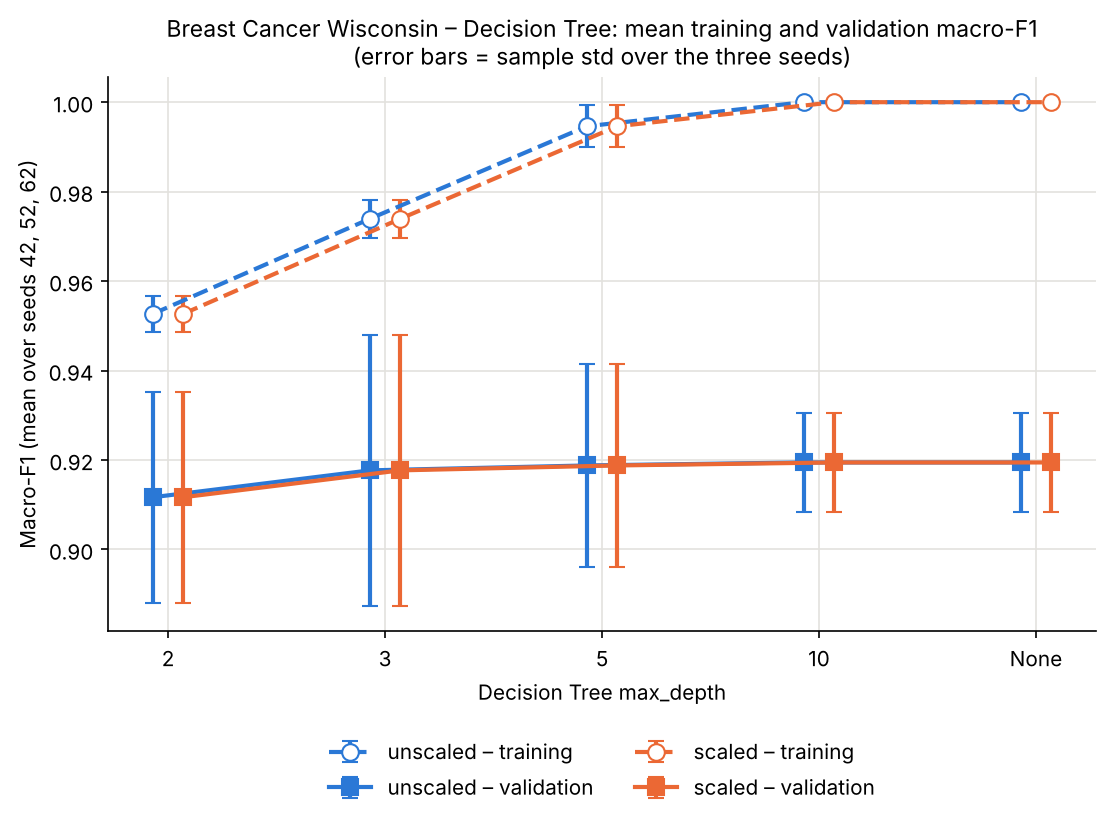

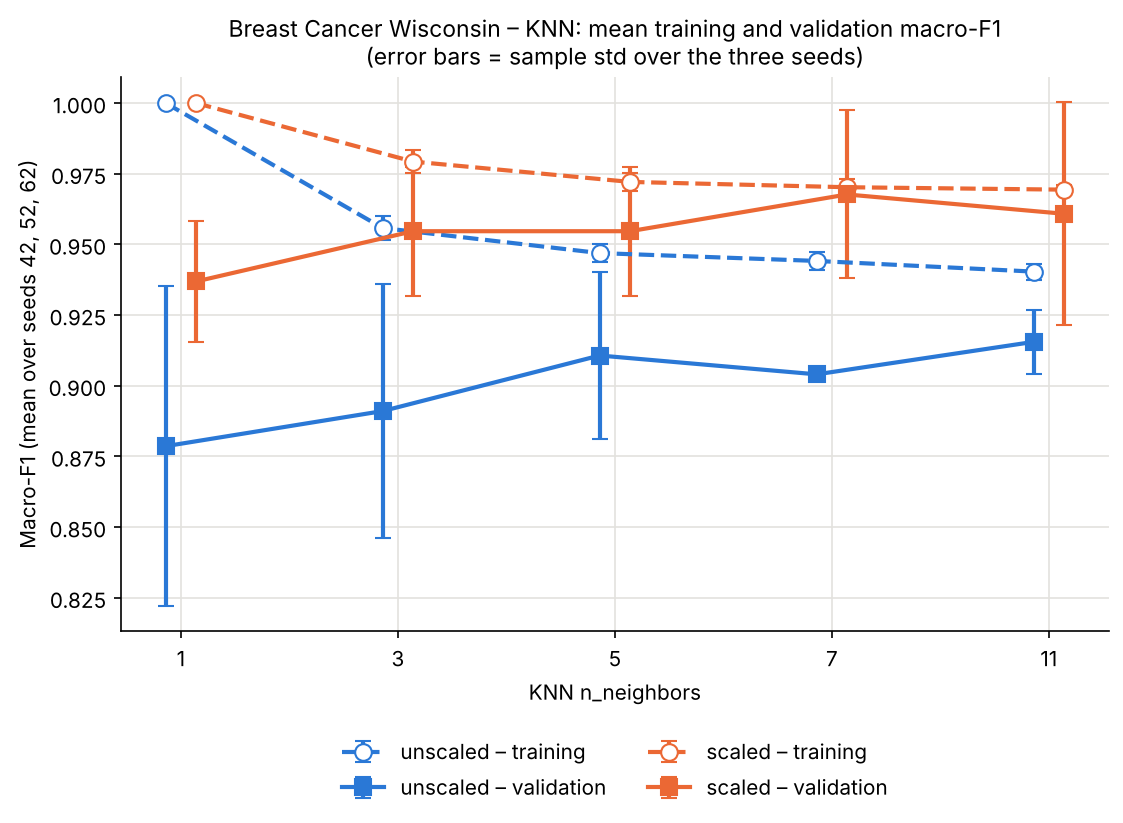

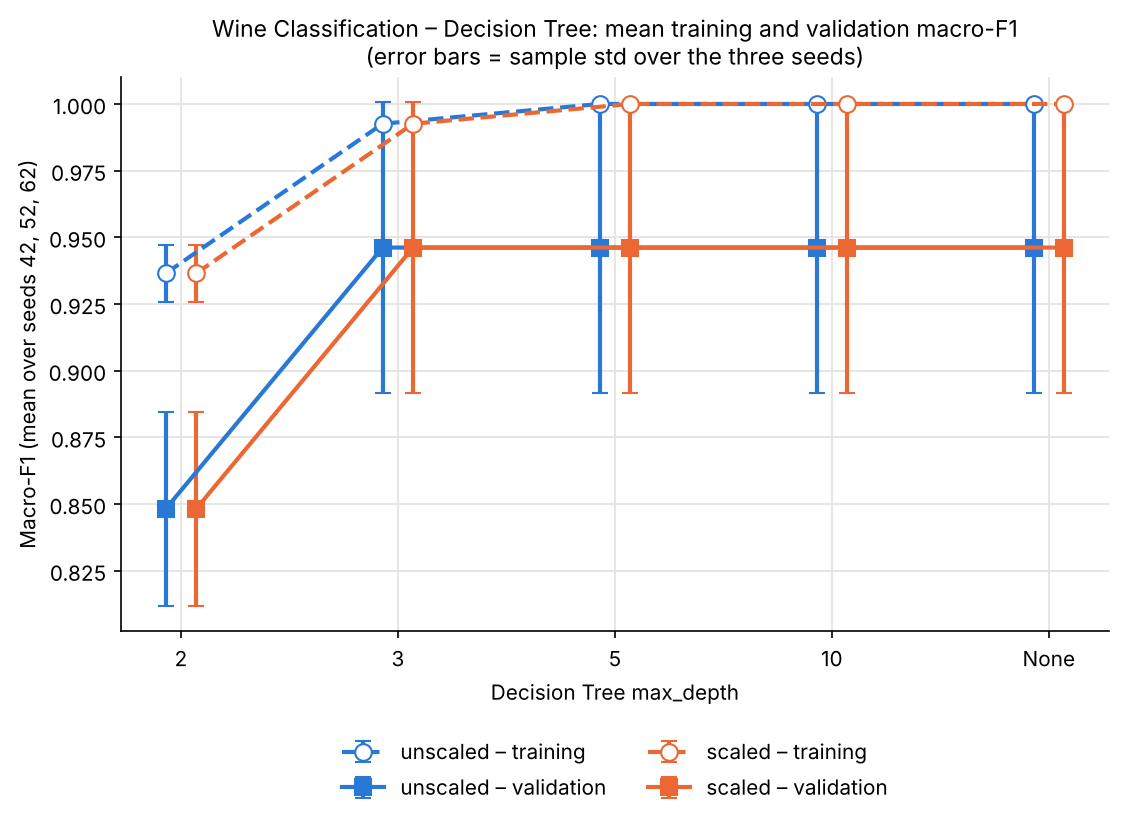

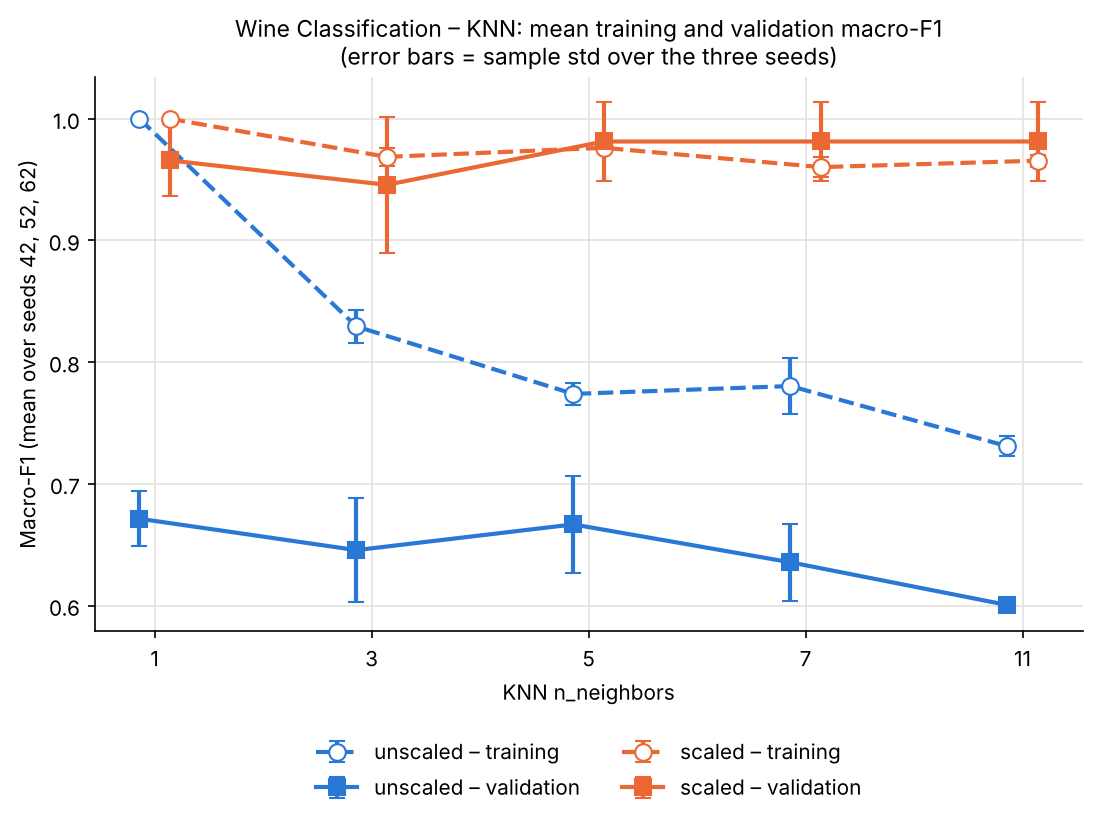

In [7]:
for name in ["breast_cancer_tree_depth_comparison", "breast_cancer_knn_neighbors_comparison",
             "wine_tree_depth_comparison", "wine_knn_neighbors_comparison"]:
    display(Image(filename=str(FIG_DIR / f"{name}.png"), width=620))

**Answer.** No, neither of them always improved the mean validation macro-F1.

* **Tree depth.** Breast Cancer: 0.9117 (depth 2), 0.9177 (3), 0.9188 (5), 0.9195 (10), 0.9195 (None). The increase is very small (+0.008 in total) and stops after depth 10, while the training score rises to 1.0000. Wine: 0.8481 (depth 2) jumps to 0.9462 at depth 3 and then stays exactly the same for depths 5, 10 and None. In the figures the training line keeps rising while the validation line is flat, so deeper trees mostly increased the training/validation gap.
* **Neighbour count.** Breast Cancer, scaled: 0.9369 (k = 1), 0.9547 (3), 0.9547 (5), 0.9677 (7), then down to 0.9608 (11). Wine, scaled: 0.9658 (k = 1) drops to 0.9457 (k = 3) and then reaches 0.9814 for k = 5, 7 and 11. Wine, unscaled: performance goes down as k grows (0.6714 at k = 1, 0.6005 at k = 11).
* **Variation across seeds.** The sample standard deviation of validation macro-F1 over the three seeds ranges from about 0.001 to 0.057 on Breast Cancer and from 0.001 to 0.056 on Wine; for the two selected configurations it is 0.0297 and 0.0323. These spreads are larger than most differences between neighbouring parameter values (for example 0.007 between k = 7 and k = 11 on Breast Cancer), and they are visible as overlapping error bars in the figures. The standard deviations describe three overlapping splits with small validation subsets (57 and 18 samples); they are not confidence intervals.

### 11.4 How did the main classification errors differ between the two datasets?

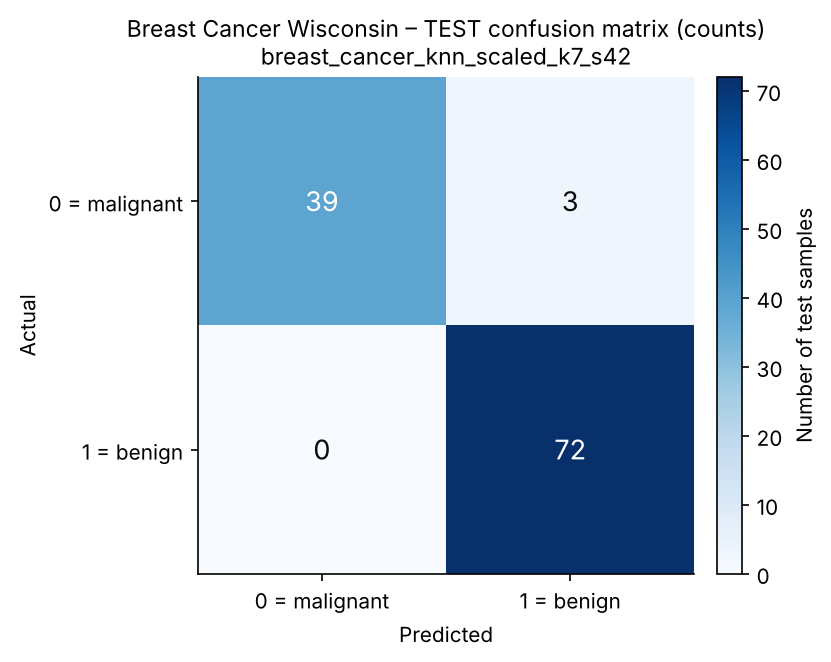

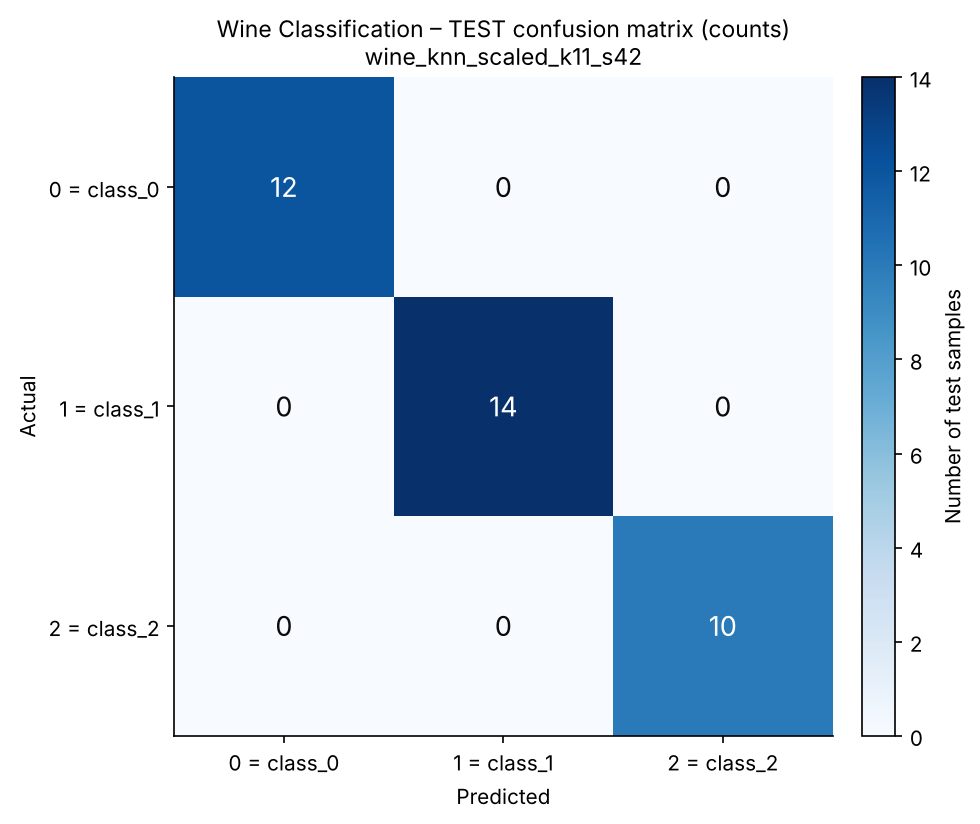

,dataset,selected_config,test_accuracy,test_macro_precision,test_macro_recall
0,breast_cancer,breast_cancer_knn_scaled_k7,0.9737,0.98,0.9643
1,wine,wine_knn_scaled_k11,1.0000,1.00,1.0000


In [8]:
for name in ["breast_cancer_test_confusion_matrix", "wine_test_confusion_matrix"]:
    display(Image(filename=str(FIG_DIR / f"{name}.png"), width=430))
display(clf_test[["dataset", "selected_config", "test_accuracy", "test_macro_precision", "test_macro_recall"]])

**Answer.**

* **Breast Cancer** (`breast_cancer_knn_scaled_k7`, 114 test samples): 3 errors, and all of them are in the same cell of the confusion matrix: actual malignant predicted as benign (false negatives with malignant as the positive class). There are no false positives (TP = 39, FN = 3, FP = 0, TN = 72). So malignant precision is 1.0000 but malignant recall is 0.9286. The errors are one-sided and of the more serious kind for this problem (missed cancers).
* **Wine** (`wine_knn_scaled_k11`, 36 test samples): the confusion matrix is purely diagonal (12, 14, 10). There is no off-diagonal confusion between any pair of classes, so no main error type exists on the test set. The only error of this configuration in the whole experiment is one validation sample under seed 62.

The difference is therefore: a small number of one-directional errors in the two-class medical dataset, and no test errors in the three-class Wine dataset. Because the Wine test set has only 36 samples, this does not mean that the Wine model can never make an error.

### 11.5 How did K-Means agreement with the true classes differ between datasets?

In [9]:
ari = km_summary[["dataset", "representation", "val_ari_mean", "val_ari_std"]].merge(
    km_test[["dataset", "representation", "test_ari", "test_cluster_counts"]], on=["dataset", "representation"])
with pd.option_context("display.max_colwidth", None):
    display(ari)

,dataset,representation,val_ari_mean,val_ari_std,test_ari,test_cluster_counts
0,breast_cancer,unscaled,0.5043,0.1064,0.5585,cluster 0: 86; cluster 1: 28
1,breast_cancer,scaled,0.5813,0.1424,0.7354,cluster 0: 74; cluster 1: 40
2,wine,unscaled,0.3613,0.0680,0.3733,cluster 0: 14; cluster 1: 10; cluster 2: 12
3,wine,scaled,1.0000,0.0000,0.9088,cluster 0: 13; cluster 1: 13; cluster 2: 10


**Answer.** ARI compares the cluster partition with the class partition and corrects for chance (1 = identical partitions, about 0 = random agreement). It is not a classification accuracy.

| Dataset | Representation | Mean validation ARI (std) | Test ARI (seed 42) |
|---|---|---|---|
| Breast Cancer | unscaled | 0.504 (0.106) | 0.559 |
| Breast Cancer | scaled | 0.581 (0.142) | 0.735 |
| Wine | unscaled | 0.361 (0.068) | 0.373 |
| Wine | scaled | 1.000 (0.000) | 0.909 |

* **Wine** depends strongly on scaling. Unscaled, the clusters mostly follow `proline` and mix the classes: in the test contingency table one cluster contains 2 class_0, 5 class_1 and 7 class_2 wines and another contains 9 class_1 and 3 class_2 wines. Scaled, the three clusters are almost the three classes: only one class_1 wine is placed in the cluster that holds the 12 class_0 wines.
* **Breast Cancer** shows a moderate agreement in both representations. Unscaled, one cluster is purely malignant (28 cases) but the other mixes 72 benign with 14 malignant cases. Scaled, the mixing is smaller (69 benign + 5 malignant in one cluster, 37 malignant + 3 benign in the other). On validation the two representations are not clearly different (the difference of the means, 0.077, is below the seed standard deviations).

So with scaled features the K-Means partition agrees with the classes more closely on Wine (test ARI 0.909) than on Breast Cancer (0.735), while with unscaled features the order is reversed (0.373 against 0.559). In both datasets some true classes are mixed inside clusters, which is expected because K-Means never uses the labels.

### 11.6 What one change would you investigate next, and why?

**Answer (future work, not a completed result).** I would replace the three overlapping training/validation repetitions with **stratified k-fold cross-validation** (for example 5 folds, repeated with several seeds) on the 80% non-test data, keeping the same fixed test set.

Reason: the validation subsets used here are very small (57 samples for Breast Cancer and 18 for Wine). The top configurations differ by only one or two validation predictions: on Wine three KNN settings were exactly tied and the choice was made by the alphabetical rule, and on Breast Cancer the gap between k = 7 and k = 11 (0.007) is much smaller than the seed standard deviation (0.030). With cross-validation every non-test sample would be used for validation once per repetition, so the means would rest on many more predictions and the comparison between configurations would be more reliable. This has not been run; it is only a proposal for the next step.

## 12. Required Run and Output Inventory

### 12.1 Run counts

In [10]:
fit_counts = pd.DataFrame({
    "dataset": DATASETS,
    "classifier fits": [int((runs["dataset"] == d).sum()) for d in DATASETS],
    "K-Means fits": [int((km_runs["dataset"] == d).sum()) for d in DATASETS],
})
fit_counts["model fits"] = fit_counts["classifier fits"] + fit_counts["K-Means fits"]
display(fit_counts)
total_fits = int(fit_counts["model fits"].sum())
print(f"Classifier fits: {len(runs)}  +  K-Means fits: {len(km_runs)}  =  {total_fits} model fits")
assert len(runs) == 132 and len(km_runs) == 12 and total_fits == 144
assert runs["run_id"].is_unique and km_runs["run_id"].is_unique
print("Unique dataset/configuration combinations:", summary["config_id"].nunique(), "(each repeated for 3 seeds)")
print("The 2 classifier and 4 clustering test evaluations reuse seed-42 fitted models and add no fits.")

,dataset,classifier fits,K-Means fits,model fits
0,breast_cancer,66,6,72
1,wine,66,6,72


Classifier fits: 132  +  K-Means fits: 12  =  144 model fits
Unique dataset/configuration combinations: 44 (each repeated for 3 seeds)
The 2 classifier and 4 clustering test evaluations reuse seed-42 fitted models and add no fits.


### 12.2 The six result files

In [11]:
required = {"classifier_runs.csv": (runs, 132), "classifier_summary.csv": (summary, 44),
            "classifier_test.csv": (clf_test, 2), "kmeans_runs.csv": (km_runs, 12),
            "kmeans_summary.csv": (km_summary, 4), "kmeans_test.csv": (km_test, 4)}
rows = []
for filename, (df, n_required) in required.items():
    rows.append({"csv_file": f"results/{filename}", "required rows": n_required, "rows in file": len(df),
                 "breast_cancer rows": int((df["dataset"] == "breast_cancer").sum()),
                 "wine rows": int((df["dataset"] == "wine").sum()),
                 "has dataset column": "dataset" in df.columns,
                 "OK": len(df) == n_required})
csv_inventory = pd.DataFrame(rows)
display(csv_inventory)
assert csv_inventory["OK"].all()

,csv_file,required rows,rows in file,breast_cancer rows,wine rows,has dataset column,OK
0,results/classifier_runs.csv,132,132,66,66,True,True
1,results/classifier_summary.csv,44,44,22,22,True,True
2,results/classifier_test.csv,2,2,1,1,True,True
3,results/kmeans_runs.csv,12,12,6,6,True,True
4,results/kmeans_summary.csv,4,4,2,2,True,True
5,results/kmeans_test.csv,4,4,2,2,True,True


### 12.3 Figures and supporting evidence

In [12]:
def count(pattern):
    return sorted(p.name for p in FIG_DIR.glob(pattern))

figure_groups = {
    "EDA – class distribution": count("*_class_distribution.png"),
    "EDA – correlation heatmap": count("*_correlation_heatmap.png"),
    "EDA – boxplots": count("*_boxplots_*.png"),
    "Classification – tree-depth comparison": count("*_tree_depth_comparison.png"),
    "Classification – KNN neighbour-count comparison": count("*_knn_neighbors_comparison.png"),
    "Classification – test confusion matrix": count("*_test_confusion_matrix.png"),
    "Classification – test ROC": count("*_test_roc_curve*.png"),
    "Clustering – class-versus-cluster (two-panel)": count("*_kmeans_test_*.png"),
}
required_min = [2, 2, 2, 2, 2, 2, 2, 4]
fig_inventory = pd.DataFrame({
    "figure group": list(figure_groups),
    "required (at least)": required_min,
    "files found": [len(v) for v in figure_groups.values()],
})
display(fig_inventory)
total_figures = int(fig_inventory["files found"].sum())
print(f"Total figure files: {total_figures} (required: at least 18)")
assert total_figures >= 18 and (fig_inventory["files found"] >= fig_inventory["required (at least)"]).all()
for group, files in figure_groups.items():
    print(f"\n{group}:")
    for f in files:
        print("  figures/" + f)

,figure group,required (at least),files found
0,EDA – class distribution,2,2
1,EDA – correlation heatmap,2,2
2,EDA – boxplots,2,5
3,Classification – tree-depth comparison,2,2
4,Classification – KNN neighbour-count comparison,2,2
5,Classification – test confusion matrix,2,2
6,Classification – test ROC,2,2
7,Clustering – class-versus-cluster (two-panel),4,4


Total figure files: 21 (required: at least 18)

EDA – class distribution:
  figures/breast_cancer_class_distribution.png
  figures/wine_class_distribution.png

EDA – correlation heatmap:
  figures/breast_cancer_correlation_heatmap.png
  figures/wine_correlation_heatmap.png

EDA – boxplots:
  figures/breast_cancer_boxplots_error.png
  figures/breast_cancer_boxplots_mean.png
  figures/breast_cancer_boxplots_worst.png
  figures/wine_boxplots_first_seven.png
  figures/wine_boxplots_last_six.png

Classification – tree-depth comparison:
  figures/breast_cancer_tree_depth_comparison.png
  figures/wine_tree_depth_comparison.png

Classification – KNN neighbour-count comparison:
  figures/breast_cancer_knn_neighbors_comparison.png
  figures/wine_knn_neighbors_comparison.png

Classification – test confusion matrix:
  figures/breast_cancer_test_confusion_matrix.png
  figures/wine_test_confusion_matrix.png

Classification – test ROC:
  figures/breast_cancer_test_roc_curve.png
  figures/wine_test_ro

**Supporting outputs kept in the two notebooks** (in addition to the six CSV files):

| Supporting output | Where |
|---|---|
| Dataset overview and class-label mapping | Section 1.2 of each notebook |
| Quality-check tables (missing values, duplicates, IQR outliers, dtypes) | Sections 2.1–2.3 |
| Descriptive-statistics table | Section 3.1 |
| Nine-row split summary, split checks and row indices | Section 4.2 (indices also in `results/<dataset>_split_indices.csv`) |
| Before/after scaling display (seed 42) | Section 5.3 |
| 66-row run table and 22-row summary | Section 8.2 |
| Per-class classification report | Section 9.1 |
| Manual metric check | Section 9.2 |
| Two class-versus-cluster contingency tables per dataset (four in total) | Section 10.2 |